# Data Preprocessing

In [ ]:
from IPython.display import Image

In [ ]:
import pandas as pd
from io import StringIO
import sys

csv_data = \
'''A,B,C,D
1.0,2.0,3.0,4.0
5.0,6.0,,8.0
10.0,11.0,12.0,'''

if (sys.version_info < (3, 0)):
    csv_data = unicode(csv_data)

df = pd.read_csv(StringIO(csv_data))
df

,A,B,C,D
0,1.0,2.0,3.0,4.0
1,5.0,6.0,NaN,8.0
2,10.0,11.0,12.0,NaN


In [ ]:
df.isnull().sum() # 결측값 개수 확인

,0
A,0
B,0
C,1
D,1


In [ ]:
# `values` 속성으로 넘파이 배열로 변환
df.values

array([[ 1.,  2.,  3.,  4.],
       [ 5.,  6., nan,  8.],
       [10., 11., 12., nan]])

In [ ]:
df.dropna(axis = 0) # axis = 0 이면 결측값이 있는 행을 삭제, axis = 1이면 열을 삭제

,A,B,C,D
0,1.0,2.0,3.0,4.0


In [ ]:
df.dropna(how="all") # 모두 결측값을 가지는 행을 삭제

,A,B,C,D
0,1.0,2.0,3.0,4.0
1,5.0,6.0,NaN,8.0
2,10.0,11.0,12.0,NaN


In [ ]:
# nan이 아닌 값이 4개 이하인 행을 삭제
df.dropna(thresh=4)

,A,B,C,D
0,1.0,2.0,3.0,4.0


In [ ]:
# 특정 열 (C)에 결측값이 있는 행을 삭제
df.dropna(subset=['C'])

,A,B,C,D
0,1.0,2.0,3.0,4.0
2,10.0,11.0,12.0,NaN


In [ ]:
from sklearn.impute import SimpleImputer
import numpy as np

# imputer 결측치 대체 객체 생성
imr = SimpleImputer(missing_values=np.nan, strategy="mean")
# df에서 결측치 대체를 위한 평균 값 계산
imr = imr.fit(df.values)
# 결측치 변환
imputed_data = imr.transform(df.values)
imputed_data

array([[ 1. ,  2. ,  3. ,  4. ],
       [ 5. ,  6. ,  7.5,  8. ],
       [10. , 11. , 12. ,  6. ]])

In [ ]:
# 만약 행을 중심으로 평균을 통해 결측값을 대체하고 싶다면 다음의 방법을 지원
from sklearn.preprocessing import FunctionTransformer
# 입력 df에 대해 전치 후 fit 계산하고 다시 전치하는 객체 정의
ftr = FunctionTransformer(lambda x : imr.fit_transform(x.T).T )
imputed_data = ftr.fit_transform(df.values)
imputed_data

array([[ 1.        ,  2.        ,  3.        ,  4.        ],
       [ 5.        ,  6.        ,  6.33333333,  8.        ],
       [10.        , 11.        , 12.        , 11.        ]])

In [ ]:
# SimpleInputer과 결과는 동일하지만 학습데이터와 테스트 데이터가 존재할 때 역할이 달라짐
# imputer는 학습데이터에 대해 평균값을 학습하여 학습과 테스트 데이터에 대해 동일하게 결측값을 대체하지만 fillna는 각 데이터에 대해 서로 다른 표본에 대해 평균값을 계산하고 결측값을 대체하는 차이가 존재
df.fillna(df.mean())

,A,B,C,D
0,1.0,2.0,3.0,4.0
1,5.0,6.0,7.5,8.0
2,10.0,11.0,12.0,6.0


In [ ]:
# fillna() 메서드의 method 매개변수를 사용하여 누락된 값을 채울 수도 있다. bfill 또는 backfill은 누락된 값을 다음 행의 값으로 채운다 ffill 또는 pad는 누락된 값을 이전 행의 값으로 채운다
df.fillna(method='bfill')

/tmp/ipykernel_1280/2328416953.py:2: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method='bfill')


,A,B,C,D
0,1.0,2.0,3.0,4.0
1,5.0,6.0,12.0,8.0
2,10.0,11.0,12.0,NaN


In [ ]:
df.fillna(method='ffill')

/tmp/ipykernel_1280/1193302488.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method='ffill')


,A,B,C,D
0,1.0,2.0,3.0,4.0
1,5.0,6.0,3.0,8.0
2,10.0,11.0,12.0,8.0


## 범주형 데이터

In [ ]:
df1 = pd.DataFrame([['green', 'M', 10.1, 'class2'],
                   ['red', 'L', 13.5, 'class1'],
                   ['blue', 'XL', 15.3, 'class2']])
df1.columns = ['color', 'size', 'price', 'class_label']
df1

,color,size,price,class_label
0,green,M,10.1,class2
1,red,L,13.5,class1
2,blue,XL,15.3,class2


In [ ]:
sizeMapping = {'M' : 1, "L" : 2, "XL" : 3}
df1['size'] = df1['size'].map(sizeMapping)
df1

,color,size,price,class_label
0,green,1,10.1,class2
1,red,2,13.5,class1
2,blue,3,15.3,class2


In [ ]:
inv_size_mapping = {v: k for k, v in sizeMapping.items()} # inverse mapping 만들어서 변환
df1['size'].map(inv_size_mapping)

,size
0,M
1,L
2,XL


In [ ]:
# 각 클래스에 대해 정수를 지정
# np.unique(df1['class_label']) 중복 제거한 np array 반환
# enumerate로 (0, 'class1') (1, 'class2') (2, 'class3') 생성
class_mapping = {label : idx for idx, label in enumerate(np.unique(df1['class_label']))}
class_mapping

{'class1': 0, 'class2': 1}

In [ ]:
df1['class_label'] = df1['class_label'].map(class_mapping)
df1

,color,size,price,class_label
0,green,1,10.1,1
1,red,2,13.5,0
2,blue,3,15.3,1


In [ ]:
from sklearn.preprocessing import LabelEncoder
classLe = LabelEncoder()
y = classLe.fit_transform(df1['class_label'].values)
y
# 바로 컬럼에 반영하고 싶으면
# df1['class_label'] = classLe.fit_transform(df1['class_label'].values)

array([1, 0, 1])

In [ ]:
# One-hot 인코딩
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

X = df1[['color', 'size', 'price']].values
cTransf = ColumnTransformer([('onehot', OneHotEncoder(), [0]), ('nothing', 'passthrough', [1,2])])
cTransf.fit_transform(X)

array([[0.0, 1.0, 0.0, 1, 10.1],
       [0.0, 0.0, 1.0, 2, 13.5],
       [1.0, 0.0, 0.0, 3, 15.3]], dtype=object)

In [ ]:
# 원-핫 인코딩 via 판다스
pd.get_dummies(df1[['price', 'color', 'size']])

,price,size,color_blue,color_green,color_red
0,10.1,1,False,True,False
1,13.5,2,False,False,True
2,15.3,3,True,False,False


In [ ]:
pd.get_dummies(df1[['price', 'color', 'size']], columns=['size']) # one-hot 인코딩할 컬럼 지정 가능

,price,color,size_1,size_2,size_3
0,10.1,green,True,False,False
1,13.5,red,False,True,False
2,15.3,blue,False,False,True


In [ ]:
df_wine = pd.read_csv('https://archive.ics.uci.edu/'
                      'ml/machine-learning-databases/wine/wine.data',
                      header=None)

df_wine.columns = ['Class label', 'Alcohol', 'Malic acid', 'Ash',
                   'Alcalinity of ash', 'Magnesium', 'Total phenols',
                   'Flavanoids', 'Nonflavanoid phenols', 'Proanthocyanins',
                   'Color intensity', 'Hue', 'OD280/OD315 of diluted wines',
                   'Proline']
print(f"wine class : {np.unique(df_wine['Class label'])}")
df_wine.head(10)

NameError: name 'pd' is not defined

In [ ]:
from sklearn.model_selection import train_test_split

X, y = df_wine.iloc[ : , 1: ].values, df_wine.iloc[:, 0].values
# random_state=0	데이터 분할 결과를 재현할 수 있도록 난수 고정
# stratify=y	클래스별 비율을 유지하면서 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 0, stratify = y)

## 특성 스케일링 맞추기

In [ ]:
from sklearn.preprocessing import MinMaxScaler
mms = MinMaxScaler()
X_train_norm = mms.fit_transform(X_train)
y_train_norm = mms.transform(X_test) # 테스트도 학습데이터에서 fit한 결과를 함께 사용해야하므로 fit_transform이 아닌 이전에 fit한 결과를 바탕으로 그냥 transform

## 표준화

In [ ]:
from sklearn.preprocessing import StandardScaler
stdSc = StandardScaler()
X_train_std = stdSc.fit_transform(X_train)
X_test_std = stdSc.transform(X_test)

## Robust

In [ ]:
from sklearn.preprocessing import RobustScaler
rbScaler = RobustScaler()
X_train_robust = rbScaler.fit_transform(X_train)
X_test_robust = rbScaler.transform(X_test)
X_train_robust

array([[ 0.41651032,  2.00322581, -0.05797101, ..., -0.16666667,
        -0.65245203, -0.23094904],
       [ 0.52157598, -0.20322581,  0.95652174, ...,  0.86363636,
         0.15778252,  1.05002338],
       [ 0.49906191, -0.22258065,  0.95652174, ...,  0.68181818,
        -0.08955224,  1.14352501],
       ...,
       [ 0.61163227,  2.06129032, -0.4057971 , ..., -1.16666667,
        -1.26652452, -0.48340346],
       [-0.82926829, -0.48709677, -0.20289855, ...,  0.07575758,
         0.26865672,  0.39738195],
       [-0.2739212 ,  1.30645161,  0.08695652, ...,  0.68181818,
         0.26865672, -0.39364189]], shape=(124, 13))

MaxAbsScaler는 각 특성별로 데이터를 최대 절댓값으로 나눈다 따라서 각 특성의 최댓값은 1이 되고 전체 특성은 [-1, 1] 범위로 변경된다

In [ ]:
from sklearn.preprocessing import MaxAbsScaler
mas = MaxAbsScaler()
X_train_maxabs = mas.fit_transform(X_train)
X_test_maxabs = mas.transform(X_test)

StandardScaler, MinMaxScaler, RobustScaler, MaxAbsScaler에 대응하는 scale(), minmax_scale(), robust_scale(), maxabs_scale() 함수가 있고 이 함수들은 1차원 배열도 입력 받을 수 있다

In [ ]:
from sklearn.preprocessing import scale, minmax_scale, robust_scale, maxabs_scale
ex = np.array([0, 1, 2, 3, 4, 5])
print('StandardScaler:', scale(ex))
print('MinMaxScaler:', minmax_scale(ex))
print('RobustScaler:', robust_scale(ex))
print('MaxAbsScaler:', maxabs_scale(ex))

StandardScaler: [-1.46385011 -0.87831007 -0.29277002  0.29277002  0.87831007  1.46385011]
MinMaxScaler: [0.  0.2 0.4 0.6 0.8 1. ]
RobustScaler: [-1.  -0.6 -0.2  0.2  0.6  1. ]
MaxAbsScaler: [0.  0.2 0.4 0.6 0.8 1. ]


In [ ]:
# MaxAbsScaler, maxabs_scaler()는 데이터를 중앙에 맞추지 않기 때문에 희소 행렬을 사용할 수 있음

from scipy import sparse
from sklearn.preprocessing import MaxAbsScaler

mas = MaxAbsScaler()
X_train_sparse = sparse.csr_matrix(X_train)

X_train_maxabs = mas.fit_transform(X_train_sparse)

In [ ]:
# 마지막으로 Normalizer 클래스와 normalize() 함수는 특성이 아니라 샘플별로 정규화를 수행하고 희소 행렬도 처리할 수 있음
# 기본적으로 샘플의 L2 노름이 1이 되도록 정규화

from sklearn.preprocessing import Normalizer

nrm = Normalizer()
X_train_l2 = nrm.fit_transform(X_train)

In [ ]:
ex_2f = np.vstack((ex[1:], ex[1:]**2)) ## 1행을 제곱한 데이터를 추가
ex_2f

array([[ 1,  2,  3,  4,  5],
       [ 1,  4,  9, 16, 25]])

In [ ]:
l2_norm = np.sqrt(np.sum(ex_2f**2, axis=1))
print(l2_norm)
ex_2f / l2_norm.reshape(-1,1) # -1은 numpy가 뒤의 1을 바탕으로 1열이 되도록 행을 자동으로 계산

[ 7.41619849 31.28897569]


array([[0.13483997, 0.26967994, 0.40451992, 0.53935989, 0.67419986],
       [0.03196014, 0.12784055, 0.28764125, 0.51136222, 0.79900347]])

In [ ]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(penalty = "l1", C = 1.0, solver = 'liblinear', random_state= 1)
lr.fit(X_train_std, y_train)
print('훈련 정확도:', lr.score(X_train_std, y_train))
print('테스트 정확도:', lr.score(X_test_std, y_test))

훈련 정확도: 1.0
테스트 정확도: 1.0


In [ ]:
lr.intercept_ # 학습 결과의 편향을 출력 liblinear 에서 다분류는 one vs rest로 하나의 클래스에 대해 나머지를 분류해내는 분류기 3개를 구성하므로 편향도 3개

array([-1.26392152, -1.21596534, -2.37040177])

In [ ]:
lr.coef_[lr.coef_!=0].shape # 실제 0이 아닌 가중치 수가 23임을 통해 필요없는 가중치는 0으로 규제된 것을 확인

(23,)

In [ ]:
lr.coef_

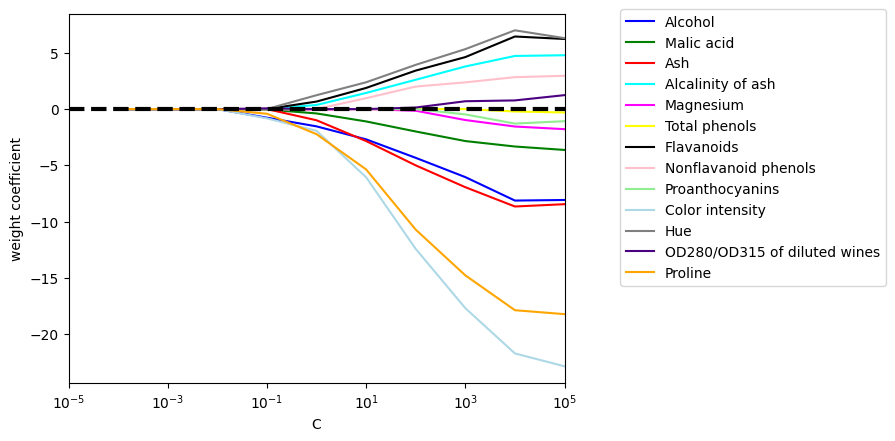

In [ ]:
# class 1에 대하여 분류에 영향을 주는 attribute 분석
import matplotlib.pyplot as plt

fig = plt.figure()
ax = plt.subplot(111)

colors = ['blue', 'green', 'red', 'cyan',
          'magenta', 'yellow', 'black',
          'pink', 'lightgreen', 'lightblue',
          'gray', 'indigo', 'orange']

weights, params = [], []

for c in range(-4, 6) :
  lr = LogisticRegression(penalty = "l1", C = 10**c, solver = 'liblinear', random_state=0)
  lr.fit(X_train_std, y_train)
  weights.append(lr.coef_[1])
  params.append(10**c)

weights = np.array(weights)
# weight.shape[1]는 열 개수이므로 range하여 0..13이 됨
for column, color in zip(range(weights.shape[1]), colors) :
  plt.plot(params, weights[:, column], label = df_wine.columns[column+1], color = color)

plt.axhline(0, color='black', linestyle='--', linewidth=3)
plt.xlim([10**(-5), 10**5])
plt.ylabel('weight coefficient')
plt.xlabel('C')
plt.xscale('log')
plt.legend(loc='upper left')
ax.legend(loc='upper center',
          bbox_to_anchor=(1.38, 1.03),
          ncol=1, fancybox=True)
# plt.savefig('images/04_07.png', dpi=300,
#             bbox_inches='tight', pad_inches=0.2)
plt.show()

